In [1]:
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Thiết bị:", "GPU" if torch.cuda.is_available() else "CPU")

print("Notebook đã kết nối thành công!")

PyTorch: 2.15.0+cpu
Torchvision: 0.29.2+cpu
Thiết bị: CPU
Notebook đã kết nối thành công!


In [3]:
from torchvision import datasets

print("Bắt đầu kiểm tra bộ dữ liệu CIFAR-10...")

Bắt đầu kiểm tra bộ dữ liệu CIFAR-10...


In [4]:
# Tải bộ dữ liệu CIFAR-10

train_data = datasets.CIFAR10(
    root="../data",
    train=True,
    download=True
)

test_data = datasets.CIFAR10(
    root="../data", 
    train=False,
    download=True
)

print("Số lượng ảnh huấn luyện:", len(train_data))
print("Số lượng ảnh kiểm tra:", len(test_data))


100.0%


Số lượng ảnh huấn luyện: 50000
Số lượng ảnh kiểm tra: 10000


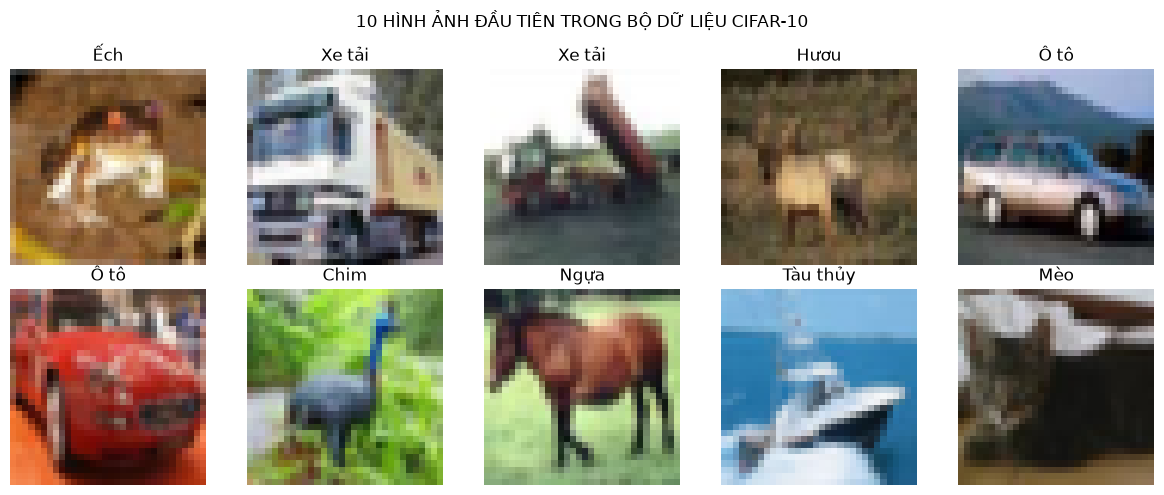

In [5]:

import matplotlib.pyplot as plt

# Danh sách tên 10 lớp bằng tiếng Việt
ten_lop = [
    "Máy bay",
    "Ô tô",
    "Chim",
    "Mèo",
    "Hươu",
    "Chó",
    "Ếch",
    "Ngựa",
    "Tàu thủy",
    "Xe tải"
]

# Hiển thị 10 hình ảnh đầu tiên
plt.figure(figsize=(12, 5))

for i in range(10):
    anh, nhan = train_data[i]

    plt.subplot(2, 5, i + 1)
    plt.imshow(anh)
    plt.title(ten_lop[nhan])
    plt.axis("off")

plt.suptitle("10 HÌNH ẢNH ĐẦU TIÊN TRONG BỘ DỮ LIỆU CIFAR-10")
plt.tight_layout()
plt.show()


In [6]:

# Lấy hình ảnh đầu tiên trong tập huấn luyện
anh, nhan = train_data[0]

print("THÔNG TIN BỘ DỮ LIỆU CIFAR-10")
print("--------------------------------")
print("Số lượng ảnh huấn luyện:", len(train_data))
print("Số lượng ảnh kiểm tra:", len(test_data))
print("Kích thước một hình ảnh:", anh.size)
print("Nhãn của hình ảnh đầu tiên:", ten_lop[nhan])
print("Số lớp phân loại:", len(ten_lop))


THÔNG TIN BỘ DỮ LIỆU CIFAR-10
--------------------------------
Số lượng ảnh huấn luyện: 50000
Số lượng ảnh kiểm tra: 10000
Kích thước một hình ảnh: (32, 32)
Nhãn của hình ảnh đầu tiên: Ếch
Số lớp phân loại: 10


In [7]:

from torchvision import transforms

# Các bước tiền xử lý hình ảnh
phep_bien_doi = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Đã tạo các bước tiền xử lý dữ liệu!")


Đã tạo các bước tiền xử lý dữ liệu!


In [9]:
from torchvision import datasets

# Tạo tập dữ liệu huấn luyện có tiền xử lý
du_lieu_huan_luyen = datasets.CIFAR10(
    root="../data",
    train=True,
    download=False,
    transform=phep_bien_doi
)

# Tạo tập dữ liệu kiểm tra có tiền xử lý
du_lieu_kiem_tra = datasets.CIFAR10(
    root="../data",
    train=False,
    download=False,
    transform=phep_bien_doi
)

print("Đã tạo bộ dữ liệu có tiền xử lý!")
print("Số ảnh huấn luyện:", len(du_lieu_huan_luyen))
print("Số ảnh kiểm tra:", len(du_lieu_kiem_tra))

Đã tạo bộ dữ liệu có tiền xử lý!
Số ảnh huấn luyện: 50000
Số ảnh kiểm tra: 10000


In [10]:
from torch.utils.data import random_split
import torch

# Chia dữ liệu thành tập huấn luyện và tập xác thực
du_lieu_train, du_lieu_val = random_split(
    du_lieu_huan_luyen,
    [45000, 5000],
    generator=torch.Generator().manual_seed(42)
)

print("Đã chia dữ liệu thành công!")
print("Số ảnh huấn luyện:", len(du_lieu_train))
print("Số ảnh xác thực:", len(du_lieu_val))

Đã chia dữ liệu thành công!
Số ảnh huấn luyện: 45000
Số ảnh xác thực: 5000


In [11]:
from torch.utils.data import DataLoader

# Tạo các nhóm dữ liệu
train_loader = DataLoader(
    du_lieu_train,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    du_lieu_val,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    du_lieu_kiem_tra,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

print("Đã tạo DataLoader thành công!")
print("Số batch huấn luyện:", len(train_loader))
print("Số batch xác thực:", len(val_loader))
print("Số batch kiểm tra:", len(test_loader))

Đã tạo DataLoader thành công!
Số batch huấn luyện: 1407
Số batch xác thực: 157
Số batch kiểm tra: 313


In [12]:
# Lấy một batch dữ liệu huấn luyện
anh, nhan = next(iter(train_loader))

print("KIỂM TRA DỮ LIỆU")
print("-------------------------")
print("Kích thước batch ảnh:", anh.shape)
print("Kích thước batch nhãn:", nhan.shape)
print("Kích thước một ảnh:", anh[0].shape)
print("Số ảnh trong batch:", len(anh))
print("Nhãn của ảnh đầu tiên:", ten_lop[nhan[0].item()])

KIỂM TRA DỮ LIỆU
-------------------------
Kích thước batch ảnh: torch.Size([32, 3, 224, 224])
Kích thước batch nhãn: torch.Size([32])
Kích thước một ảnh: torch.Size([3, 224, 224])
Số ảnh trong batch: 32
Nhãn của ảnh đầu tiên: Ếch


In [13]:
import torch
import torch.nn as nn
from torchvision import models

# Chọn thiết bị huấn luyện
thiet_bi = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Tải mô hình ResNet18 đã được huấn luyện trước
mo_hinh = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

# Thay lớp phân loại cuối cùng thành 10 lớp
so_dac_trung = mo_hinh.fc.in_features
mo_hinh.fc = nn.Linear(so_dac_trung, 10)

# Đưa mô hình lên thiết bị
mo_hinh = mo_hinh.to(thiet_bi)

print("Đã tải mô hình ResNet18 thành công!")
print("Thiết bị sử dụng:", thiet_bi)
print("Số lớp phân loại:", 10)

Đã tải mô hình ResNet18 thành công!
Thiết bị sử dụng: cpu
Số lớp phân loại: 10


In [14]:
# Đóng băng các tham số của mô hình
for tham_so in mo_hinh.parameters():
    tham_so.requires_grad = False

# Cho phép huấn luyện lớp phân loại cuối cùng
for tham_so in mo_hinh.fc.parameters():
    tham_so.requires_grad = True

# Kiểm tra số lượng tham số được huấn luyện
so_tham_so = sum(
    tham_so.numel()
    for tham_so in mo_hinh.parameters()
    if tham_so.requires_grad
)

print("Đã thiết lập Transfer Learning!")
print("Số tham số được huấn luyện:", so_tham_so)


Đã thiết lập Transfer Learning!
Số tham số được huấn luyện: 5130


In [15]:
import torch.optim as optim

# Hàm tính toán sai số
ham_mat_mat = nn.CrossEntropyLoss()

# Bộ tối ưu hóa Adam
bo_toi_uu = optim.Adam(
    mo_hinh.fc.parameters(),
    lr=0.001
)

print("Đã thiết lập hàm mất mát!")
print("Đã thiết lập bộ tối ưu hóa Adam!")
print("Tốc độ học:", 0.001)

Đã thiết lập hàm mất mát!
Đã thiết lập bộ tối ưu hóa Adam!
Tốc độ học: 0.001


In [16]:
def huan_luyen(mo_hinh, bo_du_lieu, ham_mat_mat, bo_toi_uu, thiet_bi):
    mo_hinh.train()

    tong_mat_mat = 0
    tong_dung = 0
    tong_anh = 0

    for anh, nhan in bo_du_lieu:
        anh = anh.to(thiet_bi)
        nhan = nhan.to(thiet_bi)

        # Xóa gradient cũ
        bo_toi_uu.zero_grad()

        # Dự đoán kết quả
        du_doan = mo_hinh(anh)

        # Tính lỗi
        mat_mat = ham_mat_mat(du_doan, nhan)

        # Lan truyền ngược
        mat_mat.backward()

        # Cập nhật tham số
        bo_toi_uu.step()

        tong_mat_mat += mat_mat.item()
        _, ket_qua = torch.max(du_doan, 1)

        tong_dung += (ket_qua == nhan).sum().item()
        tong_anh += nhan.size(0)

    do_chinh_xac = 100 * tong_dung / tong_anh
    mat_mat_trung_binh = tong_mat_mat / len(bo_du_lieu)

    return mat_mat_trung_binh, do_chinh_xac


print("Đã tạo hàm huấn luyện mô hình!")

Đã tạo hàm huấn luyện mô hình!


In [17]:
def danh_gia(mo_hinh, bo_du_lieu, ham_mat_mat, thiet_bi):
    mo_hinh.eval()

    tong_mat_mat = 0
    tong_dung = 0
    tong_anh = 0

    with torch.no_grad():
        for anh, nhan in bo_du_lieu:
            anh = anh.to(thiet_bi)
            nhan = nhan.to(thiet_bi)

            du_doan = mo_hinh(anh)
            mat_mat = ham_mat_mat(du_doan, nhan)

            tong_mat_mat += mat_mat.item()

            _, ket_qua = torch.max(du_doan, 1)
            tong_dung += (ket_qua == nhan).sum().item()
            tong_anh += nhan.size(0)

    do_chinh_xac = 100 * tong_dung / tong_anh
    mat_mat_trung_binh = tong_mat_mat / len(bo_du_lieu)

    return mat_mat_trung_binh, do_chinh_xac


print("Đã tạo hàm đánh giá mô hình!")

Đã tạo hàm đánh giá mô hình!


In [18]:
so_epoch = 5

lich_su = {
    "mat_mat_train": [],
    "do_chinh_xac_train": [],
    "mat_mat_val": [],
    "do_chinh_xac_val": []
}

for epoch in range(so_epoch):
    print(f"\nEpoch [{epoch + 1}/{so_epoch}]")

    mat_mat_train, chinh_xac_train = huan_luyen(
        mo_hinh, train_loader, ham_mat_mat, bo_toi_uu, thiet_bi
    )

    mat_mat_val, chinh_xac_val = danh_gia(
        mo_hinh, val_loader, ham_mat_mat, thiet_bi
    )

    lich_su["mat_mat_train"].append(mat_mat_train)
    lich_su["do_chinh_xac_train"].append(chinh_xac_train)
    lich_su["mat_mat_val"].append(mat_mat_val)
    lich_su["do_chinh_xac_val"].append(chinh_xac_val)

    print(f"Lỗi huấn luyện: {mat_mat_train:.4f}")
    print(f"Độ chính xác huấn luyện: {chinh_xac_train:.2f}%")
    print(f"Lỗi xác thực: {mat_mat_val:.4f}")
    print(f"Độ chính xác xác thực: {chinh_xac_val:.2f}%")

print("\nĐÃ HUẤN LUYỆN XONG RESNET18!")


Epoch [1/5]
Lỗi huấn luyện: 0.8185
Độ chính xác huấn luyện: 72.84%
Lỗi xác thực: 0.6237
Độ chính xác xác thực: 78.40%

Epoch [2/5]
Lỗi huấn luyện: 0.6465
Độ chính xác huấn luyện: 77.66%
Lỗi xác thực: 0.6010
Độ chính xác xác thực: 79.36%

Epoch [3/5]
Lỗi huấn luyện: 0.6196
Độ chính xác huấn luyện: 78.67%
Lỗi xác thực: 0.5874
Độ chính xác xác thực: 79.62%

Epoch [4/5]
Lỗi huấn luyện: 0.6098
Độ chính xác huấn luyện: 79.02%
Lỗi xác thực: 0.5833
Độ chính xác xác thực: 79.60%

Epoch [5/5]
Lỗi huấn luyện: 0.6034
Độ chính xác huấn luyện: 79.10%
Lỗi xác thực: 0.5640
Độ chính xác xác thực: 80.46%

ĐÃ HUẤN LUYỆN XONG RESNET18!


In [19]:
import os

# Tạo thư mục lưu mô hình
os.makedirs("../checkpoints", exist_ok=True)

# Lưu trọng số mô hình ResNet18
torch.save(
    mo_hinh.state_dict(),
    "../checkpoints/resnet18_cifar10.pth"
)

print("Đã lưu mô hình ResNet18 thành công!")
print("Vị trí: checkpoints/resnet18_cifar10.pth")

Đã lưu mô hình ResNet18 thành công!
Vị trí: checkpoints/resnet18_cifar10.pth


In [20]:
# Đánh giá ResNet18 trên tập kiểm tra
mat_mat_test, do_chinh_xac_test = danh_gia(
    mo_hinh,
    test_loader,
    ham_mat_mat,
    thiet_bi
)

print("KẾT QUẢ ĐÁNH GIÁ RESNET18")
print("------------------------------")
print(f"Lỗi kiểm tra: {mat_mat_test:.4f}")
print(f"Độ chính xác kiểm tra: {do_chinh_xac_test:.2f}%")

KẾT QUẢ ĐÁNH GIÁ RESNET18
------------------------------
Lỗi kiểm tra: 0.5770
Độ chính xác kiểm tra: 79.98%


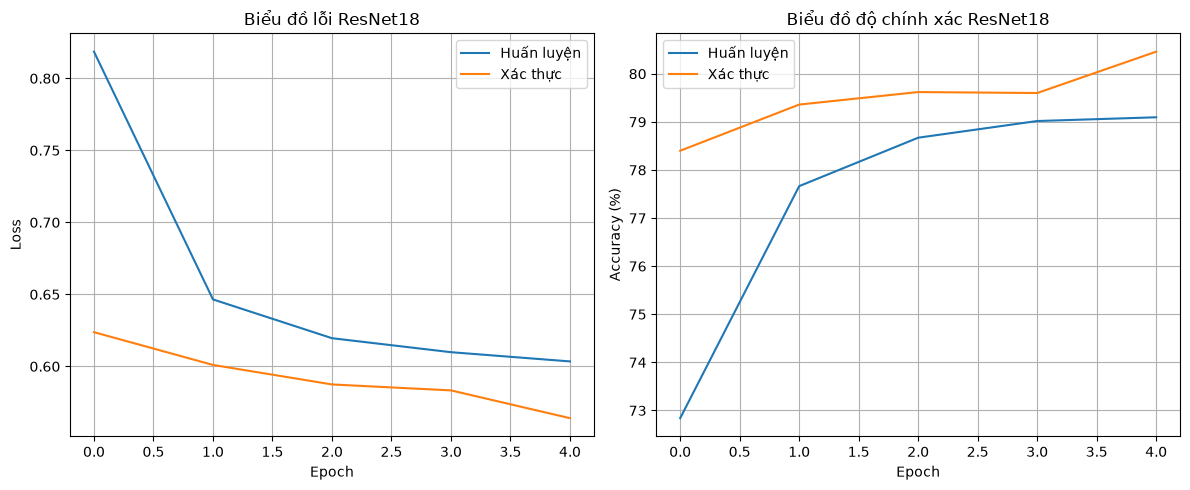

In [21]:
import matplotlib.pyplot as plt

# Tạo biểu đồ gồm 2 phần
plt.figure(figsize=(12, 5))

# Biểu đồ lỗi
plt.subplot(1, 2, 1)
plt.plot(lich_su["mat_mat_train"], label="Huấn luyện")
plt.plot(lich_su["mat_mat_val"], label="Xác thực")
plt.title("Biểu đồ lỗi ResNet18")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()

# Biểu đồ độ chính xác
plt.subplot(1, 2, 2)
plt.plot(lich_su["do_chinh_xac_train"], label="Huấn luyện")
plt.plot(lich_su["do_chinh_xac_val"], label="Xác thực")
plt.title("Biểu đồ độ chính xác ResNet18")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

<Figure size 1000x800 with 0 Axes>

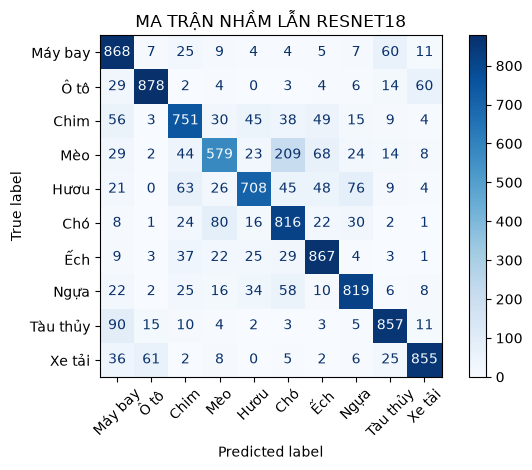

In [23]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np

# Thu thập nhãn thật và kết quả dự đoán
nhan_that = []
nhan_du_doan = []

mo_hinh.eval()

with torch.no_grad():
    for anh, nhan in test_loader:
        anh = anh.to(thiet_bi)

        du_doan = mo_hinh(anh)
        _, ket_qua = torch.max(du_doan, 1)

        nhan_that.extend(nhan.numpy())
        nhan_du_doan.extend(ket_qua.cpu().numpy())

# Tạo ma trận nhầm lẫn
ma_tran = confusion_matrix(nhan_that, nhan_du_doan)

# Hiển thị ma trận
plt.figure(figsize=(10, 8))

hien_thi = ConfusionMatrixDisplay(
    confusion_matrix=ma_tran,
    display_labels=ten_lop
)

hien_thi.plot(
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("MA TRẬN NHẦM LẪN RESNET18")
plt.tight_layout()
plt.show()

In [25]:
import os
import pandas as pd

# Tạo bảng kết quả ResNet18
ket_qua = pd.DataFrame({
    "Mo hinh": ["ResNet18"],
    "Test Loss": [mat_mat_test],
    "Test Accuracy (%)": [do_chinh_xac_test]
})

# Lưu kết quả thành file CSV
os.makedirs("../results", exist_ok=True)

ket_qua.to_csv(
    "../results/resnet18_results.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Đã lưu kết quả đánh giá ResNet18!")
print(ket_qua)

Đã lưu kết quả đánh giá ResNet18!
    Mo hinh  Test Loss  Test Accuracy (%)
0  ResNet18   0.577047              79.98


In [26]:
# Tải mô hình VGG16 đã được huấn luyện trước
mo_hinh_vgg = models.vgg16(
    weights=models.VGG16_Weights.DEFAULT
)

# Thay lớp phân loại cuối thành 10 lớp
mo_hinh_vgg.classifier[6] = nn.Linear(4096, 10)

# Đưa mô hình lên CPU
mo_hinh_vgg = mo_hinh_vgg.to(thiet_bi)

print("Đã tải mô hình VGG16 thành công!")
print("Thiết bị sử dụng:", thiet_bi)
print("Số lớp phân loại:", 10)

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to C:\Users\DUONG (BIN)/.cache\torch\hub\checkpoints\vgg16-397923af.pth


100.0%


Đã tải mô hình VGG16 thành công!
Thiết bị sử dụng: cpu
Số lớp phân loại: 10


In [27]:
# Đóng băng các lớp đặc trưng
for tham_so in mo_hinh_vgg.features.parameters():
    tham_so.requires_grad = False

# Chỉ huấn luyện lớp phân loại cuối cùng
for tham_so in mo_hinh_vgg.classifier[6].parameters():
    tham_so.requires_grad = True

# Đếm số tham số được huấn luyện
so_tham_so_vgg = sum(
    tham_so.numel()
    for tham_so in mo_hinh_vgg.parameters()
    if tham_so.requires_grad
)

print("Đã thiết lập Transfer Learning cho VGG16!")
print("Số tham số được huấn luyện:", so_tham_so_vgg)

Đã thiết lập Transfer Learning cho VGG16!
Số tham số được huấn luyện: 119586826


In [28]:
# Hàm tính toán sai số
ham_mat_mat_vgg = nn.CrossEntropyLoss()

# Bộ tối ưu hóa Adam
bo_toi_uu_vgg = optim.Adam(
    mo_hinh_vgg.classifier[6].parameters(),
    lr=0.001
)

print("Đã thiết lập hàm mất mát cho VGG16!")
print("Đã thiết lập bộ tối ưu hóa Adam!")
print("Tốc độ học:", 0.001)

Đã thiết lập hàm mất mát cho VGG16!
Đã thiết lập bộ tối ưu hóa Adam!
Tốc độ học: 0.001


In [29]:
# Đóng băng toàn bộ mô hình VGG16
for tham_so in mo_hinh_vgg.parameters():
    tham_so.requires_grad = False

# Chỉ cho phép huấn luyện lớp phân loại cuối
for tham_so in mo_hinh_vgg.classifier[6].parameters():
    tham_so.requires_grad = True

print("Đã hoàn thiện Transfer Learning cho VGG16!")
print("Chỉ huấn luyện lớp phân loại cuối cùng.")

Đã hoàn thiện Transfer Learning cho VGG16!
Chỉ huấn luyện lớp phân loại cuối cùng.


In [30]:
from torch.utils.data import Subset, DataLoader

# Lấy một phần dữ liệu để thử nghiệm
vgg_train = Subset(du_lieu_train, range(1000))
vgg_val = Subset(du_lieu_val, range(200))

# Tạo DataLoader
vgg_train_loader = DataLoader(
    vgg_train,
    batch_size=16,
    shuffle=True,
    num_workers=0
)

vgg_val_loader = DataLoader(
    vgg_val,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

print("Đã chuẩn bị dữ liệu thử nghiệm VGG16!")
print("Ảnh huấn luyện:", len(vgg_train))
print("Ảnh xác thực:", len(vgg_val))

Đã chuẩn bị dữ liệu thử nghiệm VGG16!
Ảnh huấn luyện: 1000
Ảnh xác thực: 200


In [31]:
# Huấn luyện VGG16 trong 1 Epoch
loss_vgg, acc_vgg = huan_luyen(
    mo_hinh_vgg,
    vgg_train_loader,
    ham_mat_mat_vgg,
    bo_toi_uu_vgg,
    thiet_bi
)

print("KẾT QUẢ HUẤN LUYỆN VGG16")
print("----------------------------")
print(f"Lỗi huấn luyện: {loss_vgg:.4f}")
print(f"Độ chính xác: {acc_vgg:.2f}%")

KẾT QUẢ HUẤN LUYỆN VGG16
----------------------------
Lỗi huấn luyện: 1.1789
Độ chính xác: 58.10%


In [32]:
loss_vgg_val, acc_vgg_val = danh_gia(
    mo_hinh_vgg,
    vgg_val_loader,
    ham_mat_mat_vgg,
    thiet_bi
)

print("KẾT QUẢ ĐÁNH GIÁ VGG16")
print("--------------------------")
print(f"Lỗi xác thực: {loss_vgg_val:.4f}")
print(f"Độ chính xác xác thực: {acc_vgg_val:.2f}%")

KẾT QUẢ ĐÁNH GIÁ VGG16
--------------------------
Lỗi xác thực: 0.7649
Độ chính xác xác thực: 72.50%


In [33]:
# Tải mô hình DenseNet121 đã được huấn luyện trước
mo_hinh_dense = models.densenet121(
    weights=models.DenseNet121_Weights.DEFAULT
)

# Thay lớp phân loại cuối thành 10 lớp CIFAR-10
so_dac_trung = mo_hinh_dense.classifier.in_features
mo_hinh_dense.classifier = nn.Linear(so_dac_trung, 10)

# Đưa mô hình lên CPU
mo_hinh_dense = mo_hinh_dense.to(thiet_bi)

# Đóng băng các lớp cũ
for tham_so in mo_hinh_dense.parameters():
    tham_so.requires_grad = False

# Chỉ huấn luyện lớp phân loại cuối
for tham_so in mo_hinh_dense.classifier.parameters():
    tham_so.requires_grad = True

# Hàm mất mát và bộ tối ưu
ham_mat_mat_dense = nn.CrossEntropyLoss()

bo_toi_uu_dense = optim.Adam(
    mo_hinh_dense.classifier.parameters(),
    lr=0.001
)

print("Đã tải DenseNet121 thành công!")
print("Số lớp đầu ra:", mo_hinh_dense.classifier.out_features)

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to C:\Users\DUONG (BIN)/.cache\torch\hub\checkpoints\densenet121-a639ec97.pth


100.0%


Đã tải DenseNet121 thành công!
Số lớp đầu ra: 10


In [34]:
# Huấn luyện DenseNet121
loss_dense, acc_dense = huan_luyen(
    mo_hinh_dense,
    vgg_train_loader,
    ham_mat_mat_dense,
    bo_toi_uu_dense,
    thiet_bi
)

print("KẾT QUẢ HUẤN LUYỆN DENSENET121")
print("--------------------------------")
print(f"Lỗi huấn luyện: {loss_dense:.4f}")
print(f"Độ chính xác: {acc_dense:.2f}%")

KẾT QUẢ HUẤN LUYỆN DENSENET121
--------------------------------
Lỗi huấn luyện: 1.8991
Độ chính xác: 34.60%


In [35]:
loss_dense_val, acc_dense_val = danh_gia(
    mo_hinh_dense,
    vgg_val_loader,
    ham_mat_mat_dense,
    thiet_bi
)

print("KẾT QUẢ ĐÁNH GIÁ DENSENET121")
print("--------------------------------")
print(f"Lỗi xác thực: {loss_dense_val:.4f}")
print(f"Độ chính xác xác thực: {acc_dense_val:.2f}%")

KẾT QUẢ ĐÁNH GIÁ DENSENET121
--------------------------------
Lỗi xác thực: 1.5542
Độ chính xác xác thực: 46.50%


In [36]:
# Lưu mô hình DenseNet121
torch.save(
    mo_hinh_dense.state_dict(),
    "../checkpoints/densenet121_cifar10_trial.pth"
)

# Lưu kết quả thử nghiệm
ket_qua_dense = pd.DataFrame([{
    "Mo hinh": "DenseNet121",
    "So anh huan luyen": 1000,
    "So anh xac thuc": 200,
    "Epoch": 1,
    "Train Accuracy (%)": acc_dense,
    "Validation Accuracy (%)": acc_dense_val,
    "Validation Loss": loss_dense_val
}])

ket_qua_dense.to_csv(
    "../results/densenet121_trial_results.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Đã lưu mô hình và kết quả DenseNet121!")

Đã lưu mô hình và kết quả DenseNet121!


In [37]:
# Tạo bảng so sánh kết quả
bang_so_sanh = pd.DataFrame([
    {
        "Mô hình": "ResNet18",
        "Train Accuracy (%)": "Đã huấn luyện 5 epoch",
        "Validation Accuracy (%)": 80.46,
        "Test Accuracy (%)": 79.98
    },
    {
        "Mô hình": "VGG16",
        "Train Accuracy (%)": 58.10,
        "Validation Accuracy (%)": 72.50,
        "Test Accuracy (%)": "Chưa đánh giá"
    },
    {
        "Mô hình": "DenseNet121",
        "Train Accuracy (%)": acc_dense,
        "Validation Accuracy (%)": acc_dense_val,
        "Test Accuracy (%)": "Chưa đánh giá"
    }
])

display(bang_so_sanh)

,Mô hình,Train Accuracy (%),Validation Accuracy (%),Test Accuracy (%)
0,ResNet18,Đã huấn luyện 5 epoch,80.46,79.98
1,VGG16,58.1,72.50,Chưa đánh giá
2,DenseNet121,34.6,46.50,Chưa đánh giá


In [38]:
import os

print("KIỂM TRA FILE KẾT QUẢ")
print("----------------------")

for thu_muc in ["../checkpoints", "../results"]:
    print(f"\n{thu_muc}:")
    for ten_file in os.listdir(thu_muc):
        print("-", ten_file)

KIỂM TRA FILE KẾT QUẢ
----------------------

../checkpoints:
- densenet121_cifar10_trial.pth
- resnet18_cifar10.pth

../results:
- densenet121_trial_results.csv
- resnet18_results.csv


In [39]:
# Lưu mô hình VGG16
torch.save(
    mo_hinh_vgg.state_dict(),
    "../checkpoints/vgg16_cifar10_trial.pth"
)

# Lưu kết quả VGG16
ket_qua_vgg = pd.DataFrame([{
    "Mo hinh": "VGG16",
    "So anh huan luyen": 1000,
    "So anh xac thuc": 200,
    "Epoch": 1,
    "Train Accuracy (%)": 58.10,
    "Validation Accuracy (%)": 72.50,
    "Validation Loss": 0.7649
}])

ket_qua_vgg.to_csv(
    "../results/vgg16_trial_results.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Đã lưu VGG16 thành công!")

Đã lưu VGG16 thành công!


In [40]:
from torch.utils.tensorboard import SummaryWriter

writer = SummaryWriter("../runs/practice2")

writer.add_scalar("Accuracy/ResNet18_Test", 79.98, 1)
writer.add_scalar("Accuracy/VGG16_Validation", 72.50, 1)
writer.add_scalar("Accuracy/DenseNet121_Validation", acc_dense_val, 1)

writer.close()

print("Đã ghi dữ liệu TensorBoard!")

Đã ghi dữ liệu TensorBoard!


In [41]:
writer = SummaryWriter("../runs/practice2")

writer.add_scalar("Loss/ResNet18_Test", 0.5770, 1)
writer.add_scalar("Loss/VGG16_Validation", 0.7649, 1)
writer.add_scalar("Loss/DenseNet121_Validation", loss_dense_val, 1)

writer.close()

print("Đã ghi biểu đồ Loss vào TensorBoard!")

Đã ghi biểu đồ Loss vào TensorBoard!


In [42]:
# Hàm kiểm tra thông tin mô hình
def kiem_tra_mo_hinh(ten, mo_hinh):
    tong_tham_so = sum(p.numel() for p in mo_hinh.parameters())

    tham_so_huan_luyen = sum(
        p.numel() for p in mo_hinh.parameters()
        if p.requires_grad
    )

    print(f"\nMÔ HÌNH: {ten}")
    print("-" * 40)
    print(f"Tổng số tham số: {tong_tham_so:,}")
    print(f"Tham số đang huấn luyện: {tham_so_huan_luyen:,}")


# Kiểm tra 3 mô hình
kiem_tra_mo_hinh("ResNet18", mo_hinh)
kiem_tra_mo_hinh("VGG16", mo_hinh_vgg)
kiem_tra_mo_hinh("DenseNet121", mo_hinh_dense)


MÔ HÌNH: ResNet18
----------------------------------------
Tổng số tham số: 11,181,642
Tham số đang huấn luyện: 5,130

MÔ HÌNH: VGG16
----------------------------------------
Tổng số tham số: 134,301,514
Tham số đang huấn luyện: 40,970

MÔ HÌNH: DenseNet121
----------------------------------------
Tổng số tham số: 6,964,106
Tham số đang huấn luyện: 10,250


In [43]:
# Thay đổi Learning Rate
bo_toi_uu_dense = optim.Adam(
    mo_hinh_dense.classifier.parameters(),
    lr=0.0001
)

print("Learning Rate mới: 0.0001")
print("Batch Size: 16")

Learning Rate mới: 0.0001
Batch Size: 16


In [45]:
loss_dense_moi, acc_dense_moi = huan_luyen(
    mo_hinh_dense,
    vgg_train_loader,
    ham_mat_mat_dense,
    bo_toi_uu_dense,
    thiet_bi
)

print("KẾT QUẢ SAU KHI THAY ĐỔI LEARNING RATE")
print("--------------------------------------")
print(f"Lỗi huấn luyện: {loss_dense_moi:.4f}")
print(f"Độ chính xác: {acc_dense_moi:.2f}%")

KẾT QUẢ SAU KHI THAY ĐỔI LEARNING RATE
--------------------------------------
Lỗi huấn luyện: 1.4134
Độ chính xác: 62.00%


In [46]:
vgg_train_loader_32 = DataLoader(
    vgg_train,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

print("Batch Size mới: 32")

Batch Size mới: 32


In [47]:
loss_dense_bs32, acc_dense_bs32 = huan_luyen(
    mo_hinh_dense,
    vgg_train_loader_32,
    ham_mat_mat_dense,
    bo_toi_uu_dense,
    thiet_bi
)

print("KẾT QUẢ SAU KHI THAY ĐỔI BATCH SIZE")
print("-----------------------------------")
print(f"Lỗi huấn luyện: {loss_dense_bs32:.4f}")
print(f"Độ chính xác: {acc_dense_bs32:.2f}%")

KẾT QUẢ SAU KHI THAY ĐỔI BATCH SIZE
-----------------------------------
Lỗi huấn luyện: 1.3134
Độ chính xác: 68.90%


In [48]:
import os

for thu_muc, cac_thu_muc, cac_file in os.walk(".."):
    cac_thu_muc[:] = [
        x for x in cac_thu_muc
        if x not in [".venv", "__pycache__"]
    ]

    cap = os.path.relpath(thu_muc, "..")
    print(f"\n[{cap}]")

    for ten_file in cac_file:
        print(" -", ten_file)


[.]

[checkpoints]
 - densenet121_cifar10_trial.pth
 - resnet18_cifar10.pth
 - vgg16_cifar10_trial.pth

[data]
 - cifar-10-python.tar.gz

[data\cifar-10-batches-py]
 - batches.meta
 - data_batch_1
 - data_batch_2
 - data_batch_3
 - data_batch_4
 - data_batch_5
 - readme.html
 - test_batch

[docs]
 - data.md
 - evaluation.md
 - labs2-description.md
 - model.md
 - plan-progress-status.md
 - requirements.txt
 - training.md

[notebooks]
 - Practice2_CIFAR10.ipynb

[results]
 - densenet121_trial_results.csv
 - resnet18_results.csv
 - vgg16_trial_results.csv

[runs]

[runs\practice2]
 - events.out.tfevents.1793952167.LAPTOP-UEH44AM9.17792.0
 - events.out.tfevents.1793952408.LAPTOP-UEH44AM9.17792.1


In [49]:
import os

for thu_muc in ["../results", "../notebooks", "../docs"]:
    print(f"\n===== {thu_muc} =====")

    for ten_file in os.listdir(thu_muc):
        print("-", ten_file)


===== ../results =====
- densenet121_trial_results.csv
- resnet18_results.csv
- vgg16_trial_results.csv

===== ../notebooks =====
- Practice2_CIFAR10.ipynb

===== ../docs =====
- data.md
- evaluation.md
- labs2-description.md
- model.md
- plan-progress-status.md
- requirements.txt
- training.md
